# A1: Predicting Car Price

**Goal.** Chaky's company makes cars but struggles to set prices. We build a model that predicts
`selling_price` from a car's specs, then serve it in a small web app (`app_a1.py`).

**Workflow:** 1) Load data → 2) EDA → 3) Cleaning (rules from the brief) → 4) Train/test split →
5) Impute + encode + scale (fit on train only) → 6) Model selection with cross-validation →
7) Tune the best model → 8) Test-set evaluation → 9) Feature importance → 10) Save model → 11) Report

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, os, warnings
warnings.filterwarnings('ignore')

# Fix the random seed so every run gives the same split and the same model
SEED = 42
np.random.seed(SEED)

## 1. Load data

In [2]:
df = pd.read_csv('cars.csv')
print(df.shape)
df.head()

(8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [3]:
# Data types and missing values per column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 1.6 MB


## 2. Cleaning (rules from the assignment)

We clean **before** EDA so the plots show the data the model will actually see.

In [4]:
# owner: text -> ordinal number. First Owner=1 ... Test Drive Car=5
owner_map = {'First Owner': 1, 'Second Owner': 2, 'Third Owner': 3,
             'Fourth & Above Owner': 4, 'Test Drive Car': 5}
df['owner'] = df['owner'].map(owner_map)

# fuel: CNG and LPG are measured in km/kg, not km/l, so mileage is not comparable -> drop them
df = df[~df['fuel'].isin(['CNG', 'LPG'])]

# mileage "23.4 kmpl" -> 23.4 ; engine "1248 CC" -> 1248 ; max_power "74 bhp" -> 74
df['mileage'] = df['mileage'].str.split(' ').str[0].astype(float)
df['engine'] = df['engine'].str.split(' ').str[0].astype(float)
# a few max_power values are just "bhp" (no number) -> pd.to_numeric turns them into NaN
df['max_power'] = pd.to_numeric(df['max_power'].str.split(' ').str[0], errors='coerce')

# brand: keep only the first word of the car name ("Maruti Swift Dzire VDI" -> "Maruti")
df['brand'] = df['name'].str.split(' ').str[0]
df = df.drop(columns=['name'])

# torque: the company does not understand it, so we drop it
df = df.drop(columns=['torque'])

# Test Drive Cars are unrealistically expensive and rare -> remove them
df = df[df['owner'] != 5]

df = df.reset_index(drop=True)
print(df.shape)
df.head()

(8028, 12)


,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,seats,brand
0,2014,450000,145500,Diesel,Individual,Manual,1,23.40,1248.0,74.00,5.0,Maruti
1,2014,370000,120000,Diesel,Individual,Manual,2,21.14,1498.0,103.52,5.0,Skoda
2,2006,158000,140000,Petrol,Individual,Manual,3,17.70,1497.0,78.00,5.0,Honda
3,2010,225000,127000,Diesel,Individual,Manual,1,23.00,1396.0,90.00,5.0,Hyundai
4,2007,130000,120000,Petrol,Individual,Manual,1,16.10,1298.0,88.20,5.0,Maruti


In [5]:
# Missing values left after cleaning (we will impute them after the split)
df.isna().sum()

year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          214
engine           214
max_power        208
seats            214
brand              0
dtype: int64

## 3. Exploratory Data Analysis

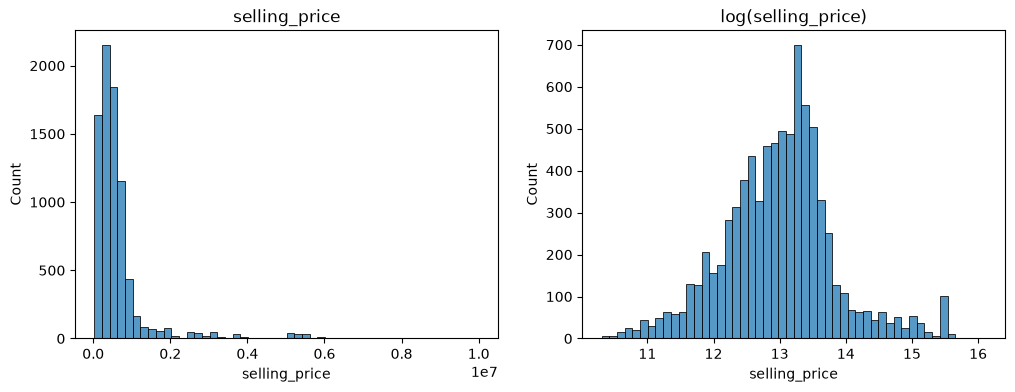

In [6]:
# The target is heavily right-skewed: a few very expensive cars.
# That is why the brief asks us to model log(price).
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['selling_price'], bins=50, ax=ax[0]).set_title('selling_price')
sns.histplot(np.log(df['selling_price']), bins=50, ax=ax[1]).set_title('log(selling_price)')
plt.show()

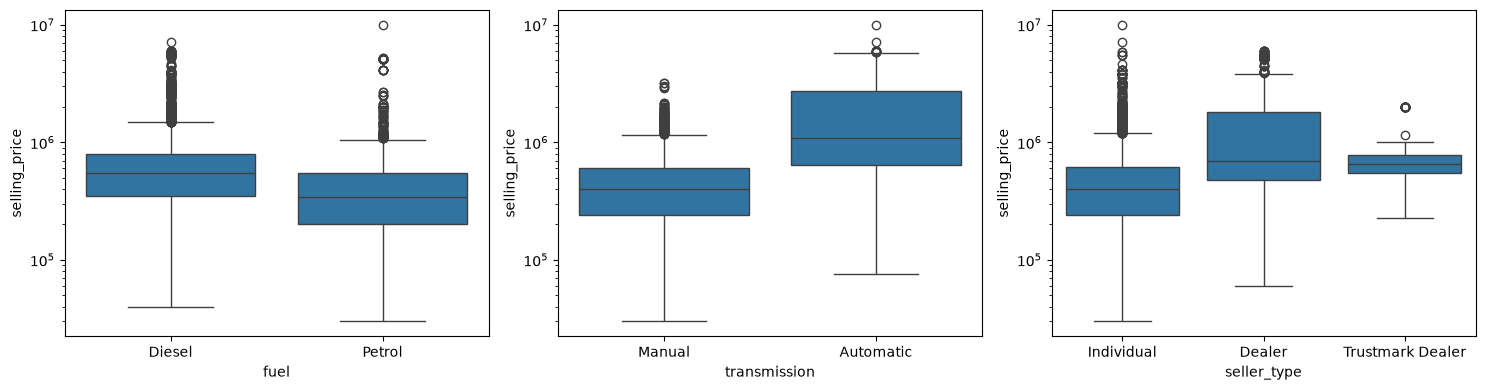

In [7]:
# Categorical features vs price
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ['fuel', 'transmission', 'seller_type']):
    sns.boxplot(data=df, x=col, y='selling_price', ax=a)
    a.set_yscale('log')
plt.tight_layout(); plt.show()

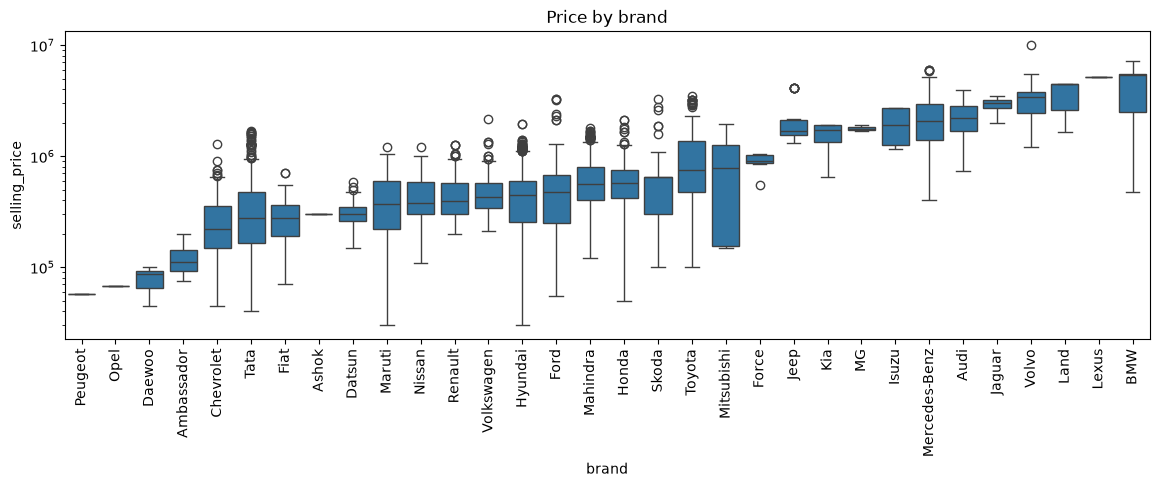

In [8]:
# Brands: how many cars and median price per brand
plt.figure(figsize=(14, 4))
order = df.groupby('brand')['selling_price'].median().sort_values().index
sns.boxplot(data=df, x='brand', y='selling_price', order=order)
plt.yscale('log'); plt.xticks(rotation=90); plt.title('Price by brand'); plt.show()

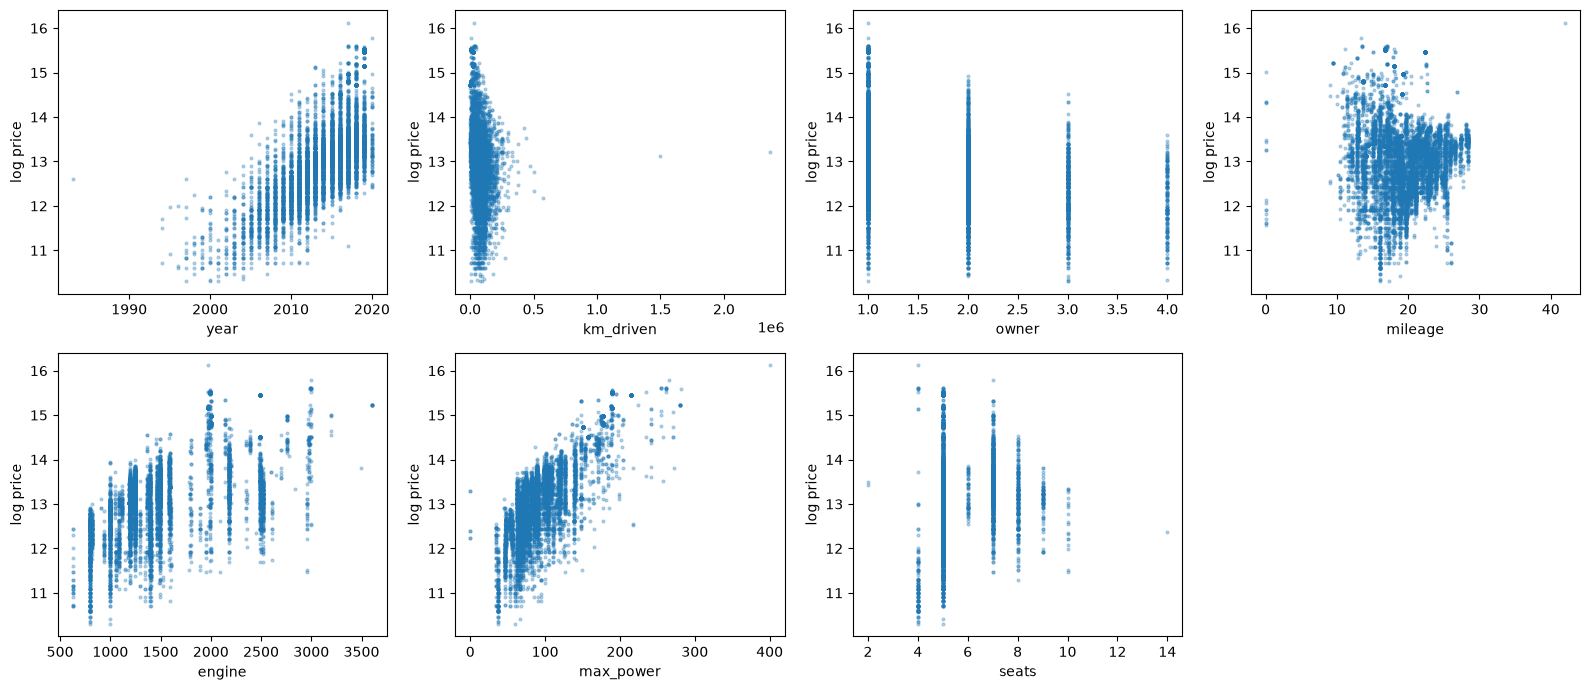

In [11]:
# Numeric features vs log price
num = ['year', 'km_driven', 'owner', 'mileage', 'engine', 'max_power', 'seats']
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, col in zip(ax.ravel(), num):
    a.scatter(df[col], np.log(df['selling_price']), s=4, alpha=0.3)
    a.set_xlabel(col); a.set_ylabel('log price')
ax.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

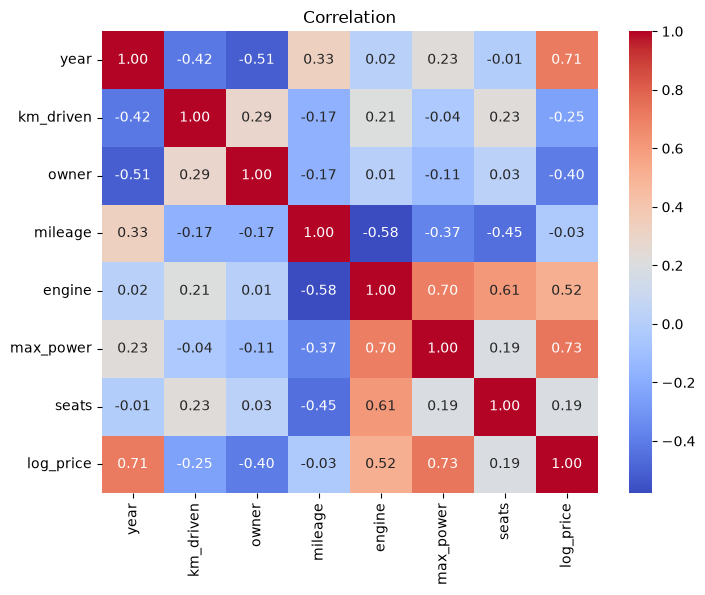

In [12]:
# Correlation matrix of numeric features (with log price)
corr = df[num].assign(log_price=np.log(df['selling_price'])).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation'); plt.show()

**EDA notes.** `max_power` and `year` correlate most strongly with log price; `engine` is also
strong but overlaps with `max_power`. `km_driven` and `owner` are negatively correlated with price
(older, more used cars are cheaper). Automatic cars and dealer sales are pricier.

## 4. Train / test split

In [13]:
X = df.drop(columns=['selling_price'])
y = np.log(df['selling_price'])   # log transform the label (brief requirement)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

(6422, 11) (1606, 11)


## 5. Preprocessing

Every statistic (median, mode, mean/std for scaling) is computed **on the training set only**
and then applied to the test set. This avoids data leakage.

In [14]:
num_cols = ['year', 'km_driven', 'owner', 'mileage', 'engine', 'max_power', 'seats']
cat_cols = ['fuel', 'seller_type', 'transmission', 'brand']

# Imputation values: median for numbers (robust to outliers), mode for categories
fill_values = {c: X_train[c].median() for c in num_cols}
fill_values['seats'] = X_train['seats'].mode()[0]       # seats is a count -> mode
fill_values.update({c: X_train[c].mode()[0] for c in cat_cols})
print(fill_values)

X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)

{'year': np.float64(2015.0), 'km_driven': np.float64(60000.0), 'owner': np.float64(1.0), 'mileage': np.float64(19.3), 'engine': np.float64(1248.0), 'max_power': np.float64(82.85), 'seats': np.float64(5.0), 'fuel': 'Diesel', 'seller_type': 'Individual', 'transmission': 'Manual', 'brand': 'Maruti'}


In [15]:
# One-hot encode the categorical columns. drop_first avoids a redundant column per feature.
X_train_enc = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test_enc = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)
# A brand may exist only in the test set -> align columns to the training set, filling with 0
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

# Standardise the numeric columns (mean 0, std 1) so features are on the same scale
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_enc[num_cols] = scaler.fit_transform(X_train_enc[num_cols])
X_test_enc[num_cols] = scaler.transform(X_test_enc[num_cols])
print(X_train_enc.shape)
X_train_enc.head()

(6422, 40)


,year,km_driven,owner,mileage,engine,max_power,seats,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,...,brand_Maruti,brand_Mercedes-Benz,brand_Mitsubishi,brand_Nissan,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen,brand_Volvo
2948,0.539209,-0.183281,-0.642016,1.459156,-1.316416,-1.088215,-0.436295,1,1,0,...,0,0,0,0,1,0,0,0,0,0
2412,-0.202184,-0.171335,3.604149,0.846671,-1.322408,-1.258879,-0.436295,1,1,0,...,1,0,0,0,0,0,0,0,0,0
6210,-1.190708,-0.239598,0.773372,-0.020385,-0.419696,-0.247691,-0.436295,1,0,0,...,0,0,0,0,0,0,0,0,0,0
6171,1.033471,-0.341993,-0.642016,-0.448872,1.439650,1.772125,1.669596,0,1,0,...,0,0,0,0,0,0,1,0,0,0
4201,-3.662018,0.511297,2.188761,-1.154616,1.078166,-0.670086,-0.436295,0,1,0,...,0,0,1,0,0,0,0,0,0,0


## 6. Model selection (5-fold cross-validation on the training set)

We compare a few algorithms using MSE and R² on the log price.

In [16]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate

algorithms = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.01),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(random_state=SEED),
    'Random Forest': RandomForestRegressor(random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=SEED),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in algorithms.items():
    s = cross_validate(model, X_train_enc, y_train, cv=kfold,
                       scoring=['neg_mean_squared_error', 'r2'])
    rows.append({'model': name,
                 'cv_mse': -s['test_neg_mean_squared_error'].mean(),
                 'cv_r2': s['test_r2'].mean()})
cv_results = pd.DataFrame(rows).sort_values('cv_mse')
cv_results

,model,cv_mse,cv_r2
5,Random Forest,0.044980,0.935643
6,Gradient Boosting,0.051166,0.926785
3,KNN,0.061465,0.912064
1,Ridge,0.066607,0.904742
0,Linear Regression,0.066772,0.904510
4,Decision Tree,0.075843,0.891450
2,Lasso,0.082287,0.882313


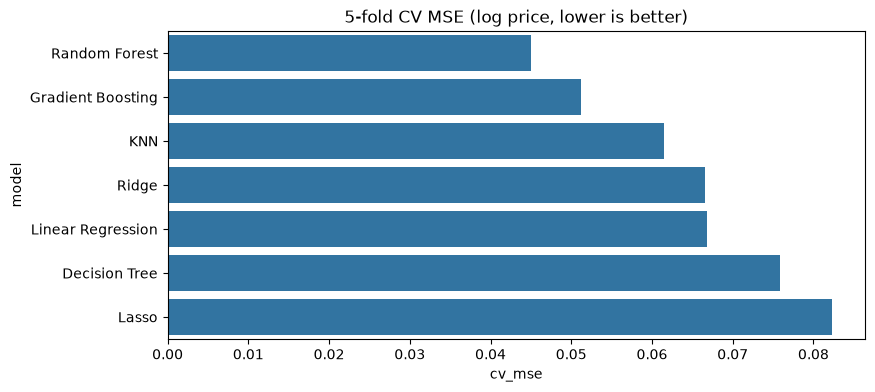

In [17]:
plt.figure(figsize=(9, 4))
sns.barplot(data=cv_results, y='model', x='cv_mse')
plt.title('5-fold CV MSE (log price, lower is better)'); plt.show()

## 7. Tune the best model (Random Forest) with grid search

In [18]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [None, 20],
    'min_samples_leaf': [1, 2],
}
grid = GridSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1), param_grid,
                    cv=kfold, scoring='neg_mean_squared_error', return_train_score=True)
grid.fit(X_train_enc, y_train)
print('best params :', grid.best_params_)
print('best CV MSE :', -grid.best_score_)
best_model = grid.best_estimator_

best params : {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
best CV MSE : 0.044658361508197124


## 8. Test-set evaluation

In [19]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

pred_log = best_model.predict(X_test_enc)
print('Test MSE (log) :', mean_squared_error(y_test, pred_log))
print('Test R2  (log) :', r2_score(y_test, pred_log))

# Transform back to real prices before comparing with the true prices (brief requirement)
pred_price = np.exp(pred_log)
true_price = np.exp(y_test)
print('Test R2  (price):', r2_score(true_price, pred_price))
print('Test MAPE       :', mean_absolute_percentage_error(true_price, pred_price))

Test MSE (log) : 0.04041191752524524
Test R2  (log) : 0.9432529576180376
Test R2  (price): 0.946372745668466
Test MAPE       : 0.14088397986718


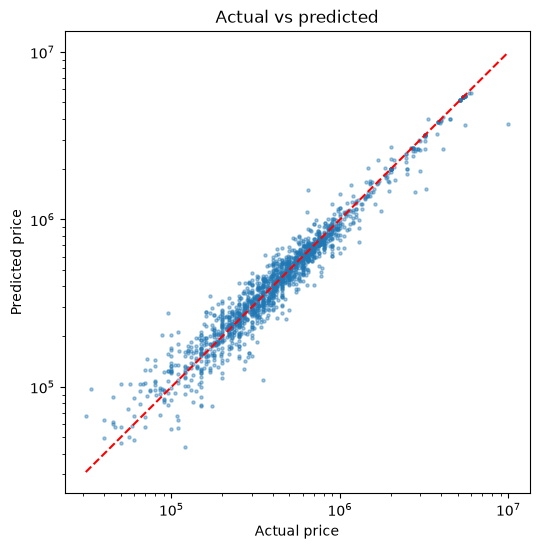

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(true_price, pred_price, s=5, alpha=0.4)
lim = [true_price.min(), true_price.max()]
plt.plot(lim, lim, 'r--')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Actual price'); plt.ylabel('Predicted price'); plt.title('Actual vs predicted')
plt.show()

## 9. Feature importance

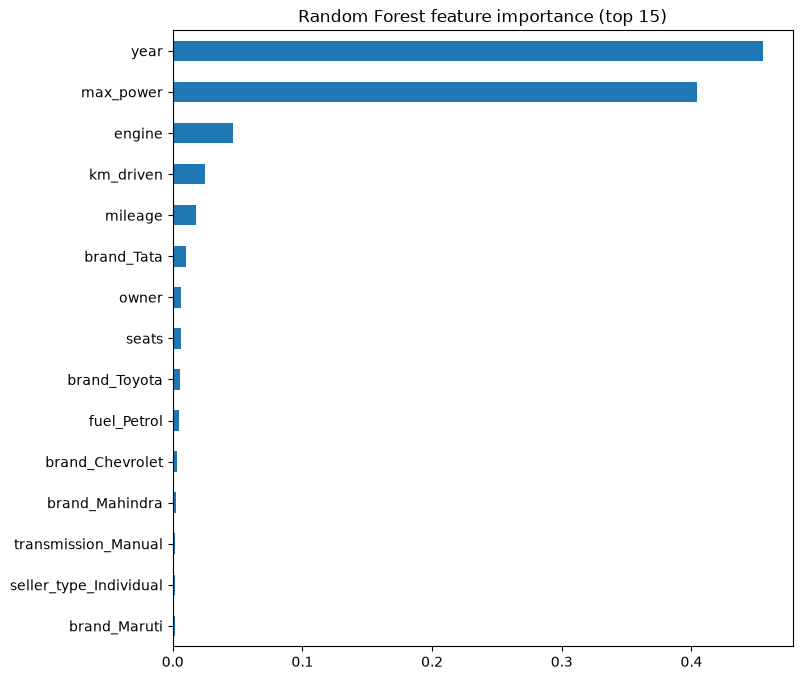

year            0.455334
max_power       0.404289
engine          0.046485
km_driven       0.024544
mileage         0.017829
brand_Tata      0.010090
owner           0.006592
seats           0.006190
brand_Toyota    0.005411
fuel_Petrol     0.005038
dtype: float64

In [21]:
imp = pd.Series(best_model.feature_importances_, index=X_train_enc.columns).sort_values()
plt.figure(figsize=(8, 8))
imp.tail(15).plot.barh()
plt.title('Random Forest feature importance (top 15)'); plt.show()
imp.sort_values(ascending=False).head(10)

In [22]:
# A second opinion: permutation importance (how much test error grows when a feature is shuffled)
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_test_enc, y_test, n_repeats=5, random_state=SEED, n_jobs=-1)
pd.Series(perm.importances_mean, index=X_test_enc.columns).sort_values(ascending=False).head(10)

year               0.554207
max_power          0.500643
engine             0.073696
brand_Tata         0.016442
mileage            0.014501
km_driven          0.012787
fuel_Petrol        0.008798
brand_Toyota       0.006509
brand_Chevrolet    0.004707
seats              0.002893
dtype: float64

## 10. Save the model for the web app

`models_a1/` holds three files:
- `car_price_model.pkl` – the tuned Random Forest
- `scaler.pkl` – the StandardScaler fitted on training data
- `model_columns.pkl` – a dict with the encoded column order, the numeric/categorical columns,
  the imputation values and the list of brands (the app needs all of these to build an input row)

In [23]:
os.makedirs('models_a1', exist_ok=True)
joblib.dump(best_model, 'models_a1/car_price_model.pkl', compress=3)
joblib.dump(scaler, 'models_a1/scaler.pkl')
joblib.dump({
    'columns': list(X_train_enc.columns),
    'num_cols': num_cols,
    'cat_cols': cat_cols,
    'fill_values': fill_values,
    'brands': sorted(df['brand'].unique()),
}, 'models_a1/model_columns.pkl')
print(os.listdir('models_a1'))

['model_columns.pkl', 'car_price_model.pkl', 'scaler.pkl']


In [24]:
# Sanity check: load the files back and predict one test car, exactly like the app will
m = joblib.load('models_a1/car_price_model.pkl')
print('predicted:', np.exp(m.predict(X_test_enc.iloc[[0]]))[0], ' actual:', true_price.iloc[0])

predicted: 226118.5757775107  actual: 225000.00000000015


## 11. Report

**Which features matter?** `year` and `max_power` dominate (about 45% and 40% of the Random Forest
importance, confirmed by permutation importance). Newer cars have lost less value to depreciation,
and a more powerful car usually belongs to a more expensive class. `engine` adds a little, then
`km_driven` and `mileage`. `owner`, `seats`, `fuel`, `seller_type` and most brand dummies carry very
little extra information. Much of that is overlap: `engine` is strongly correlated with `max_power`,
diesel cars tend to have bigger engines, and more owners usually means an older car, so once power
and age are known these features have little new to say. A few brands (e.g. Tata, Toyota) still
help because their prices differ from what their specs alone suggest.

**Which algorithms work?** Random Forest was best in cross-validation (MSE 0.045, R² 0.936 on log
price), followed by Gradient Boosting and KNN; the linear models trail at R² ≈ 0.90. Price depends on
features non-linearly and through interactions (how much extra power is worth depends on age and
brand), which trees capture by splitting the data, while a linear model fits one straight-line
effect per feature. Ridge gives the same result as plain Linear Regression because with only 40
columns and 6,400 rows there is little overfitting to fix. Lasso with alpha 0.01 is the weakest,
because it shrinks small but useful coefficients (such as brand dummies) to zero. A single Decision
Tree overfits; averaging many trees (Random Forest) cancels much of that variance, which is why it
wins. On the test set the tuned forest reaches R² 0.943 (log) / 0.946 (price) with a mean absolute
percentage error of about 14%.

**Limitations.** The model learns from second-hand Indian market prices up to 2020, so it should not
be trusted for brands or years it has rarely seen. Imputing skipped fields with the training median
gives a sensible, average-car guess, but the more fields a user leaves blank, the less precise the
prediction becomes.

In [32]:
# !python app_a1.py